# EN3160 – Assignment 02: Fitting and Alignment

| | |
|---|---|
| **Index No.** | 230352K |
| **Name** | Kumara K.B.R |
| **GitHub** | https://github.com/buddhi-rash/EN-3160-Assesment-02 |

---

This jupyter notebook contains the complete work for Assignment 02: code, results, and the discussion

| Section | Topic | tools used |
|---|---|---|
| **Q1** | Blob detection with Laplacian of Gaussian (LoG)  | Scale-space extrema, gaussian_laplace |
| **Q2** | Line and circle fitting with RANSAC | TLS, `scipy.optimize.minimize` |
| **Q3** | Superimposing an image on a planar surface | Homography (DLT), perspective warping|
| **Q4** | PCB alignment and difference imaging | SIFT, `BFMatcher`, RANSAC homography |

---
# Question 1 — Blob Detection with the Laplacian of Gaussian (LoG)

## 1.1 Objective
We want to detect the circular blobs in the sunflower field image using **blob filter(LoG) and nonmaximum suppression**, draw blob circles, and report the parameters of the **largest circles** and the **range of σ** used. 

## 1.2 Method
1. **Pre-processing.** Convert the image to grayscale and scale intensities to $[0,1]$.
2. **Scale space.** For each $\sigma$ in a set of scales, compute the scale-normalised LoG
$$L_{\text{norm}}(x,y;\sigma)=\sigma^{2}\,\nabla^{2}G_\sigma * I(x,y).$$
   The factor $\sigma^2$ makes responses comparable across scales. Stacking the responses gives a 3-D volume indexed by (scale, row, column).
3.**Extrema detection.** A voxel is a detection if it (i) is the maximum of its $5\times5\times5$ neighbourhood in (scale, y, x) and (ii) exceeds a threshold of $0.6\times$ the global maximum.
5. **Circle parameters.** A disc of radius $r$ gives its maximum response at $\sigma=r/\sqrt2$. Each detection is therefore drawn at its $(x,y)$ location with radius $r=\sqrt2\,\sigma$.

## 1.3 Parameters

| Parameter | Value | Reason |
|---|---|---|
| σ range | **4.0 to 25.0** | Covers small, distant flower centres up to the large, close ones in the foreground |
| Number of scales | 30 (linear spacing) | Fine enough that a blob is not missed between two scales |
| Threshold | 0.6 × max response | Heavy suppression of weak texture (leaves, petals, shadows) and keeps the strong dark centres |
| Neighbourhood | 5 × 5 × 5 | Removes duplicate detections of the same blob in neighbouring pixels and scales |
| Radius | $\sqrt{2}\,\sigma$ | Scale–radius relation of the LoG for a disc |

> The image is processed at its original resolution (1440 × 1440 px), so the σ range is expressed in full-resolution pixels.

## 1.4 Implementation

Image dimensions: 1440 x 1440


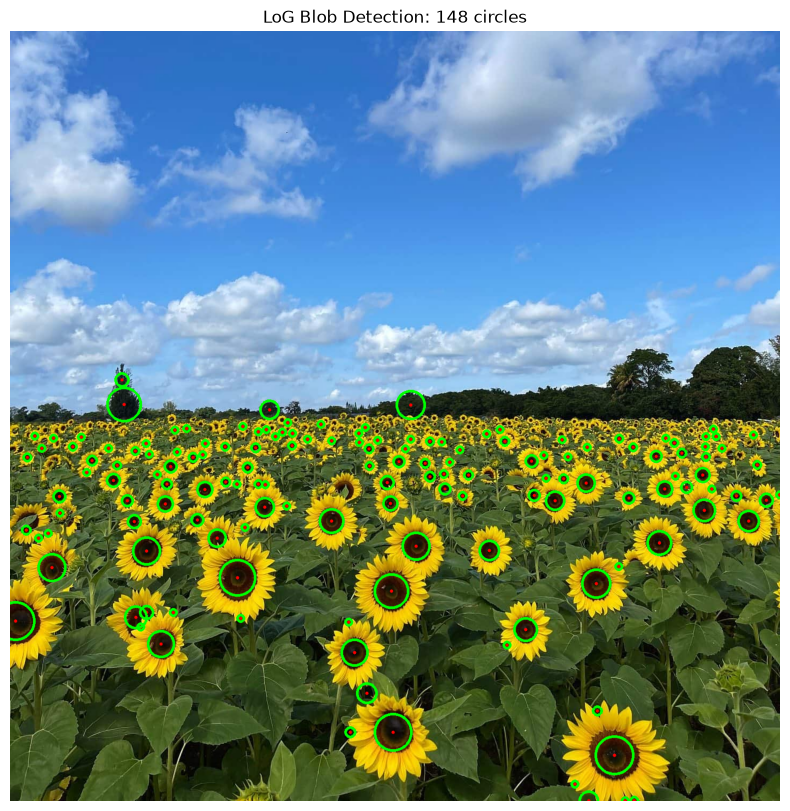

Sigma range used: 4.00 to 25.00 (30 scales)
Largest circles:
  center=(10, 1103), sigma=25.00, radius=35.36
  center=(1130, 1354), sigma=25.00, radius=35.36
  center=(716, 1311), sigma=24.28, radius=34.33
  center=(425, 1022), sigma=23.55, radius=33.31
  center=(213, 698), sigma=22.10, radius=31.26


In [ ]:
# Library import
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv
from scipy.ndimage import gaussian_laplace,maximum_filter


# Load the image, convert to grayscale and scale intensities to [0, 1] 
im_1 = cv.imread('images/the_berry_farms_sunflower_field.jpeg')
assert im_1 is not None, "Image not found"
im_1 = cv.cvtColor(im_1, cv.COLOR_BGR2GRAY)
im_1 = im_1.astype(np.float32) / 255.0
print("Image dimensions:", im_1.shape[1], "x", im_1.shape[0])


# Scale-space parameters
min_sigma = 4.0
max_sigma = 25.0
num_sigma = 30

sigmas = np.linspace(min_sigma, max_sigma, num_sigma)
responses = []

# Build the scale space: scale-normalised LoG (sigma^2 * LoG) at every sigma.
# The signed response is kept, so dark blobs (sunflower centres) give POSITIVE values.
for sigma in sigmas:
    response = gaussian_laplace(im_1, sigma=sigma)
    normalized_response = (sigma**2) * (response)
    responses.append(normalized_response)

# Stack the responses into a 3-D volume indexed by (scale, row, column)
scale_space = np.stack(responses, axis=0)
# Keep only strong responses: 60% of the global maximum
threshold = 0.6 * scale_space.max()

# 3-D non-maximum suppression: maximum over each 5x5x5 (scale, y, x) neighbourhood
local_max = maximum_filter(scale_space, size=(5, 5, 5), mode='constant')

# A detection is a local maximum in scale-space that also exceeds the threshold
peaks = ((scale_space == local_max) & (scale_space > threshold))

# Indices of the detected extrema: (scale index, row, column)
sigma_idx, y_coords, x_coords = np.where(peaks)

# Convert every extremum into a circle: centre (x, y) and radius = sqrt(2) * sigma
blobs = []

for si, y, x in zip(sigma_idx, y_coords, x_coords):
    sigma = sigmas[si]
    radius = np.sqrt(2) * sigma

    blobs.append({
        'x': int(x),
        'y': int(y),
        'sigma': float(sigma),
        'radius': float(radius),
        'response': float(scale_space[si, y, x])
    })

# Reload the colour image (converted to RGB) to draw the detected circles on
im_bgr = cv.imread('images/the_berry_farms_sunflower_field.jpeg')
im_rgb = cv.cvtColor(im_bgr, cv.COLOR_BGR2RGB)

# Draw each circle (green outline) and its centre (red dot)
for blob in blobs:
    center = (blob['x'], blob['y'])
    radius = max(1, int(round(blob['radius'])))

    cv.circle(im_rgb, center, radius, (0, 255, 0), 4)
    cv.circle(im_rgb, center, 3, (255, 0, 0), -1)

# Show the detections
plt.figure(figsize=(14, 10))
plt.imshow(im_rgb)
plt.title(f'LoG Blob Detection: {len(blobs)} circles')
plt.axis('off')
plt.show()

# Report the sigma range and the 5 largest circles (required by the task)
print(f"Sigma range used: {sigmas[0]:.2f} to {sigmas[-1]:.2f} ({num_sigma} scales)")
print("Largest circles:")
for b in sorted(blobs, key=lambda b: -b['radius'])[:5]:
    print(f"  center=({b['x']}, {b['y']}), sigma={b['sigma']:.2f}, radius={b['radius']:.2f}")


## 1.5 Results and Discussion

**Range of σ used:** $\sigma_{\min}=4.0$ to $\sigma_{\max}=25.0$ (30 scales), i.e. radii $r=\sqrt2\sigma$ from about 5.7 px to 35.4 px.

**Number of detected circles:** 148.

**Parameters of the largest circles** (radius $=\sqrt2\,\sigma$):

| Rank | Centre (x, y) | σ | Radius (px) |
|---|---|---|---|
| 1 | (10, 1103) | 25.00 | 35.36 |
| 2 | (1130, 1354) | 25.00 | 35.36 |
| 3 | (716, 1311) | 24.28 | 34.33 |
| 4 | (425, 1022) | 23.55 | 33.31 |
| 5 | (213, 698) | 22.10 | 31.26 |

**Observations**
- The detector locks onto the **dark seed-heads** of the sunflowers. The clouds and the sky are not detected, because they are bright blobs and give negative LoG values.
- The detected scale follows the **perspective of the scene**. Large circles (large σ) lie on the nearby flowers at the bottom of the image, and the circles become progressively smaller towards the horizon, where the flowers are far away.
- The largest circles belong to the flowers closest to the camera. The top two detections have σ = 25.00, which is exactly the **upper limit of the σ range**. Their true scale may therefore be larger, and a larger `max_sigma` would be needed to measure them exactly.
- A few **false positives** occur on dark structures that are not sunflowers, such as the tree at the horizon on the left. Flowers that are partly hidden or whose centres are not dark are missed or detected at the wrong size.

**Effect of the parameters.** A lower threshold adds weak detections on leaf texture and shadows. A smaller neighbourhood produces duplicate circles on the same flower. A narrower σ range loses the smallest distant flowers or the largest nearby ones. The chosen values balance these effects.

---
# Question 2 — Line and Circle Fitting with RANSAC

## 2.1 Objective
A noisy point set contains **50 points on a line** and **50 points on a circle**. We first (a) estimate the line with RANSAC, (b) remove the line's consensus set and estimate the circle from the remaining points with RANSAC, (c) plot all results
## 2.2 Data generation
The code from the task sheet (Listing 1) is used with a fixed seed.

| | Ground truth | Noise |
|---|---|---|
| Circle | centre (2, 3), radius 10 | radial, $\sigma_r=r/16=0.625$ |
| Line | $y=-x+2$, i.e. unit normal $[a,b]=\pm[0.707,\,0.707]$ and $d=\pm1.414$ | vertical, $\sigma=1$ (perpendicular $\sigma\approx0.707$) |

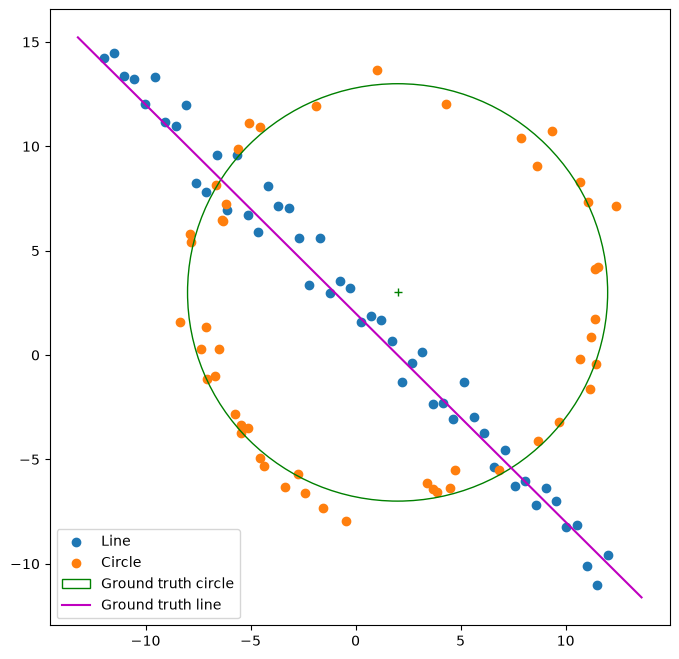

In [ ]:
# Data generation from the listing 1 of the assignment
from scipy.optimize import minimize
from scipy import linalg

np.random.seed(0)
N = 100
half_n = N // 2

r = 10
x0_gt, y0_gt = 2, 3  
s = r / 16

t = np.random.uniform(0, 2 * np.pi, half_n)
n = s * np.random.randn(half_n)
x, y = x0_gt + (r + n) * np.cos(t), y0_gt + (r + n) * np.sin(t)
X_circ = np.hstack((x.reshape(half_n, 1), y.reshape(half_n, 1)))

s = 1.0
m, b = -1, 2
x = np.linspace(-12, 12, half_n)
y = m * x + b + s * np.random.randn(half_n)
X_line = np.hstack((x.reshape(half_n, 1), y.reshape(half_n, 1)))

X = np.vstack((X_circ, X_line))  # All points
fig, ax = plt.subplots(1, 1, figsize=(8, 8))
ax.scatter(X_line[:, 0], X_line[:, 1], label="Line")
ax.scatter(X_circ[:, 0], X_circ[:, 1], label="Circle")

circle_gt = plt.Circle(
    (x0_gt, y0_gt), r, color="g", fill=False, label="Ground truth circle"
)
ax.add_patch(circle_gt)
ax.plot((x0_gt), (y0_gt), "+", color="g")

x_min, x_max = ax.get_xlim()
x_ = np.array([x_min, x_max])
y_ = m * x_ + b
plt.plot(x_, y_, color="m", label="Ground truth line")
plt.legend()
plt.show()



---
## 2.3 Part (a) — Line estimation with RANSAC

**Model.** A line is $ax+by=d$ with $\lVert[a,b]^\top\rVert=1$, where $d$ is the perpendicular distance from the origin. The constraint holds by construction: The **error** of a point is exactly its normal distance $|ax_i+by_i-d|$.

**RANSAC loop** ('ransac_line`):
1. Draw a minimal sample of **2 points** and compute the line through them.
2. Compute the normal distance of all points. Points with error `< thresh` form the **consensus set**.
3. Reject the model if the consensus has fewer than `min_inliers` points. Otherwise keep it if it has more inliers than the best so far.
4. After all iterations, **refit** the line to the best consensus set by total least squares (TLS): the line passes through the centroid, and $[a,b]$ is the right singular vector with the **smallest singular value**.

**Choice of parameters**

| Parameter | Value | Justification |
|---|---|---|
| Error threshold | **1.5** | The vertical noise has $\sigma=1$, which gives a perpendicular noise of $\approx0.71$ for a line of slope −1. A threshold of 1.5 is about $2.1\sigma$ and accepts roughly 97% of the true line points, while a strip of width 3 contains only a few circle points. |
| Minimum consensus | **40** | The set has 50 true line points, of which about 48 are expected within the threshold. A requirement of 40 tolerates a poor sample, and it is far above what a wrong line (for example a chord of the circle) can collect. |
| Iterations | 500 | For a minimal sample of 2 and an inlier ratio $w\approx0.5$, the number of iterations for 99% confidence is $\log(0.01)/\log(1-w^2)\approx16$, so 500 is more than sufficient. |

In [ ]:
# Line through two points -> (a, b, d), with unit normal [a, b] and line equation a*x + b*y = d
def line(p1, p2):
    dx, dy = p2 - p1
    nrm = np.array([-dy, dx])
    L = np.linalg.norm(nrm)
    if L < 1e-12:
        return None
    nrm = nrm / L                       # enforce |[a,b]| = 1
    return nrm[0], nrm[1], nrm @ p1     # a, b, d

# Error of each point = its perpendicular (normal) distance to the line
def line_errors(P, line):
    a, b, d = line
    return np.abs(P[:, 0]*a + P[:, 1]*b - d)   # normal distance

# Total least squares refit: the line passes through the centroid,
def fit_line_tls(P):
    c = P.mean(axis=0)
    _, _, Vt = np.linalg.svd(P - c)
    a, b = Vt[-1]                       # unit normal (smallest singular value)
    return a, b, a*c[0] + b*c[1]

# RANSAC for a line: repeatedly fit a line to 2 random points and keep the model with the largest consensus
def ransac_line(P, thresh, min_inliers, n_iter=500):
    best = None
    for _ in range(n_iter):
        # 1) minimal random sample of 2 points -> candidate line
        idx = np.random.choice(len(P), 2, replace=False)
        model = line(P[idx[0]], P[idx[1]])
        if model is None:
            continue
        # 2) consensus set: points whose normal distance is below the threshold
        err = line_errors(P, model)
        mask = err < thresh
        cnt = mask.sum()
        if cnt < min_inliers:
            continue
        # 3) keep the best model (most inliers; ties broken by the smaller total error)
        score = (cnt, -err[mask].sum())          # more inliers, then lower error
        if best is None or score > best['score']:
            best = dict(score=score, idx=idx, sample_model=model, mask=mask)
    if best is None:
        raise RuntimeError("No consensus found; relax thresh/min_inliers")
    # 4) final TLS refit using all inliers of the best model
    best['refit_model'] = fit_line_tls(P[best['mask']])   # final TLS fit on inliers
    return best

# Threshold 1.5 (~2 sigma of the perpendicular noise); at least 40 of the 100 points must agree
line_res = ransac_line(X, thresh=1.5, min_inliers=40)
a, b_, d = line_res['refit_model']
print(f"Line: normal=({a:.3f},{b_:.3f}), d={d:.3f}, inliers={line_res['mask'].sum()}")
print("Ground truth: normal=±(0.707,0.707), |d|=1.414")

Line: normal=(0.713,0.701), d=1.588, inliers=56
Ground truth: normal=±(0.707,0.707), |d|=1.414


**Result (a).** The estimated line is close to the ground truth.

| | Estimated | Ground truth |
|---|---|---|
| Unit normal $[a,b]$ | (0.713, 0.701) | (0.707, 0.707) |
| Distance $d$ | 1.588 | 1.414 |
| Inliers | 56 | 50 line points |

The normal direction differs from the ground truth by only about $0.5^\circ$. The consensus set contains **56 points, more than the 50 true line points**. The line crosses the circle, and the circle points near the two crossings fall inside the ±1.5 strip, so they are counted as line inliers. This is expected and is why step (b) fits the circle only on the remainder.

---
## 2.4 Part (b) — Circle estimation on the remaining points

The line consensus set is **subtracted** from $X$ and RANSAC is run on the remaining points (`X_rem`).

**Model.** A circle has parameters (centre $c_x,c_y$, radius $r$).
- **Minimal sample:** **3 points**. The centre is the intersection of the perpendicular bisectors of two chords, which is a $2\times2$ linear system. A near-singular determinant means that the points are collinear, and the sample is rejected.
- **Error:** the **radial error** $\big|\,\lVert p_i-c\rVert-r\,\big|$.
- **Refit:** the radial sum of squares $\sum_i(\lVert p_i-c\rVert-r)^2$ is minimised over the consensus set using `scipy.optimize.minimize` (BFGS), initialised from the 3-point circle.

**Choice of parameters**

| Parameter | Value | Justification |
|---|---|---|
| Error threshold | **1.5** | The radial noise is $\sigma_r=0.625$, so 1.5 is about $2.4\sigma_r$ and accepts about 98% of the true circle points. |
| Minimum consensus | **40** | After removing the line consensus, about 44 points remain, most of which belong to the circle. Requiring 40 of them prevents arcs from small random circles from being accepted. |
| Iterations | 500 | A 3-point sample needs $\log(0.01)/\log(1-w^3)$ iterations (about 35 even with $w=0.5$), so 500 is ample. |

In [83]:
# Circle through 3 points: the centre is the intersection of two perpendicular bisectors (2x2 linear system)
def circle_from_three_points(p1, p2, p3):
    A = 2 * np.array([p2 - p1, p3 - p1])
    rhs = np.array([p2 @ p2 - p1 @ p1, p3 @ p3 - p1 @ p1])
    if abs(np.linalg.det(A)) < 1e-9:             # collinear points
        return None
    c = np.linalg.solve(A, rhs)
    return c[0], c[1], np.linalg.norm(p1 - c)

# Radial error: | distance to the centre - radius |
def circle_errors(P, circ):
    cx, cy, rr = circ
    return np.abs(np.hypot(P[:, 0] - cx, P[:, 1] - cy) - rr)

# Refit the circle on the inliers by minimising the sum of squared radial errors with scipy.optimize.minimize
def fit_circle_opt(P, init):
    cost = lambda q: np.sum((np.hypot(P[:, 0]-q[0], P[:, 1]-q[1]) - q[2])**2)
    res = minimize(cost, init, method='BFGS')
    return tuple(res.x)

# RANSAC for a circle: same loop as for the line, but with a 3-point sample and the radial error
def ransac_circle(P, thresh, min_inliers, n_iter=500):
    best = None
    for _ in range(n_iter):
        # 1) minimal random sample of 3 points -> candidate circle
        idx = np.random.choice(len(P), 3, replace=False)
        model = circle_from_three_points(*P[idx])
        if model is None:
            continue
        # 2) consensus set: points whose radial error is below the threshold
        err = circle_errors(P, model)
        mask = err < thresh
        cnt = mask.sum()
        if cnt < min_inliers:
            continue
        # 3) keep the best model (most inliers; ties broken by the smaller total error)
        score = (cnt, -err[mask].sum())
        if best is None or score > best['score']:
            best = dict(score=score, idx=idx, sample_model=model, mask=mask)
    if best is None:
        raise RuntimeError("No consensus found; relax thresh/min_inliers")
    # 4) optimiser refit using all inliers, initialised from the 3-point circle
    best['refit_model'] = fit_circle_opt(P[best['mask']], best['sample_model'])
    return best

# Part (b): remove the line inliers, then run RANSAC for the circle on what remains
# (threshold 1.5 ~ 2.4 x the radial noise; at least 40 points must agree)
# subtract line consensus, fit circle to the remnant
X_rem = X[~line_res['mask']]
circ_res = ransac_circle(X_rem, thresh=1.5, min_inliers=40)
cx, cy, rr = circ_res['refit_model']
print(f"Circle: center=({cx:.3f},{cy:.3f}), r={rr:.3f}, inliers={circ_res['mask'].sum()}")
print("Ground truth: center=(2,3), r=10")

Circle: center=(1.870,3.065), r=9.949, inliers=43
Ground truth: center=(2,3), r=10


**Result (b).**

| | Estimated | Ground truth | Error |
|---|---|---|---|
| Centre | (1.870, 3.065) | (2, 3) | 0.15 |
| Radius | 9.949 | 10 | 0.05 (0.5%) |
| Inliers | 43 of the 44 remaining points | 50 circle points | — |

The circle is recovered accurately even though noisy points and a crossing line were present. The circle has fewer inliers (43) than the 50 generated points because roughly 6–7 circle points near the crossings had already been assigned to the line in step (a).

---
## 2.5 Part (c) — Combined visualisation

The plot below shows, in one figure:
- **All points** (blue), **line inliers** (olive) and **circle inliers** (cyan). Points that are neither remain blue.
- The **best sample** for the line (2 red crosses) and for the circle (3 red dots), i.e. the minimal samples that led to the best consensus.
- The **ground-truth** circle and line (green) and the **RANSAC** circle and line (magenta). The RANSAC models shown are the final fits (TLS for the line, optimiser for the circle) on the best consensus sets.

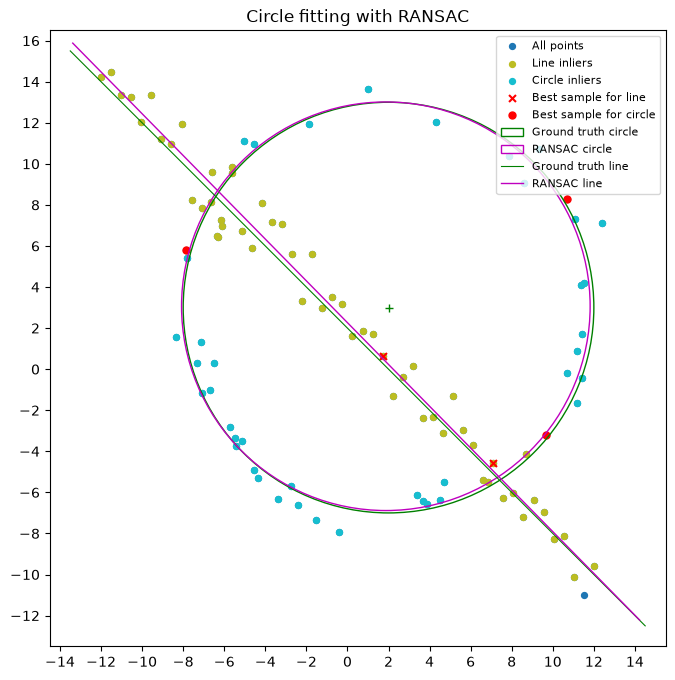

In [85]:
# Part (c): combined plot of the points, the inliers, the best samples, the RANSAC models and the ground truth
fig, ax = plt.subplots(figsize=(8, 8))

# 1. all points (blue), drawn first so the inliers sit on top
ax.scatter(X[:, 0], X[:, 1], s=18, c='tab:blue', label='All points')

# 2. line inliers (olive/yellow)
ax.scatter(X[line_res['mask'], 0], X[line_res['mask'], 1],
           s=18, c='tab:olive', label='Line inliers')

# 3. circle inliers (cyan), taken from the remnant
ax.scatter(X_rem[circ_res['mask'], 0], X_rem[circ_res['mask'], 1],
           s=18, c='tab:cyan', label='Circle inliers')

# 4. best samples (red): x for the line, dots for the circle
ls = X[line_res['idx']]
ax.scatter(ls[:, 0], ls[:, 1], marker='x', s=25, c='red', label='Best sample for line')
cs = X_rem[circ_res['idx']]
ax.scatter(cs[:, 0], cs[:, 1], marker='o', s=25, c='red', label='Best sample for circle')

# 5. ground truth circle (green) and its center
ax.add_patch(plt.Circle((x0_gt, y0_gt), r, fill=False, edgecolor='green',
                        lw=1, label='Ground truth circle'))
ax.plot(x0_gt, y0_gt, '+', color='green')

# 6. RANSAC circle (magenta)
cx, cy, rr = circ_res['refit_model']
ax.add_patch(plt.Circle((cx, cy), rr, fill=False, edgecolor='m',
                        lw=1, label='RANSAC circle'))

# 7. lines: ground truth (green) and RANSAC (magenta)
xs = np.array([-13.5, 14.5])
ax.plot(xs, m*xs + b, color='green', lw=0.8, label='Ground truth line')

a, b_, d = line_res['refit_model']
p0 = d * np.array([a, b_])            # point on the line closest to the origin
dirn = np.array([-b_, a])             # line direction
# Draw the RANSAC line from its parametric form: point on the line + t * direction
tt = np.linspace(-40, 40, 200)
lx, ly = p0[0] + tt*dirn[0], p0[1] + tt*dirn[1]
keep = (lx >= -13.5) & (lx <= 14.5)   # clip to the plot range
ax.plot(lx[keep], ly[keep], color='m', lw=1, label='RANSAC line')

ax.set_xlim(-14.5, 15.5)
ax.set_ylim(-13.5, 16.5)
ax.set_xticks(range(-14, 15, 2))
ax.set_yticks(range(-12, 17, 2))
ax.set_aspect('equal')
ax.legend(loc='upper right', fontsize=8)
ax.set_title('Circle fitting with RANSAC')
plt.show()

**Discussion (c).**
- The magenta RANSAC line and circle almost coincide with the green ground-truth curves. This confirms that RANSAC identified the correct inliers in the presence of the other structure.
- The best-sample points lie on the true structures. The line sample points lie on the line, and the three circle sample points lie spread around the circle. Well-spread samples give a stable circle, because three nearby points would give a poorly conditioned circle.
- Using the **refit on all inliers** gives a more accurate model than the minimal sample alone. The sample uses only 2 or 3 noisy points, whereas the refit averages the noise over about 40–55 points.
- The small remaining errors (line offset $d$ of about 0.17, centre error of about 0.15) come from the noise level and from the inliers that were assigned to the wrong model near the crossings.

---
## 2.6 Part (d) — What happens if the circle is fitted first?

Fitting the circle first is **less reliable**, for the following reasons.

1. **The line points are structured, not random outliers.** RANSAC assumes that outliers are unrelated to the model. Here the 50 line points form a second geometric structure, and models fitted to it can compete with the true circle.
2. **The circle's consensus set is contaminated.** The line passes through the circle, so line points near the two crossings lie within the radial threshold of the circle and are counted as circle inliers. The consensus then exceeds the 50 true circle points, and the best-scoring circle is pulled towards these points. (A quick test with the same thresholds gave a consensus of about 60 points, about 10 of which were actually line points.)
3. **A near-straight circle can compete.** A circle through three line points has a very large radius and is almost a straight line. It can collect most of the 50 line points within the threshold and compete with the true circle (about 49 inliers), so RANSAC may return the wrong model.
4. **The minimal sample is harder to draw.** A circle needs 3 points. With about half of the data belonging to the circle, the probability of an all-circle sample is about $0.5^3=1/8$, compared with $0.5^2=1/4$ for a 2-point line sample, so more iterations are needed.
5. **The error propagates to the second stage.** Removing the contaminated circle consensus also removes about 10 line points. In the quick test, only about 40 points remained, of which only about 39 lay on the line, so with the same `min_inliers = 40` the line fit failed. Even when it succeeds, the line is estimated from fewer and more biased points.

**Conclusion.** The order matters. The **line should be fitted first**: it is the simpler model (2 parameters, 2-point samples), and its consensus set is a thin strip that is easy to separate. After the strip is removed, what remains is mostly circle points, and the circle fit is clean. In general, a RANSAC pipeline should fit the simplest model, or the one with the most distinct consensus set, first.

---
# Question 3 — Superimposing an Image on a Planar Surface

## 3.1 Objective
Superimpose a flag (or another image) on a **planar surface** of a photograph. The user clicks four points on the plane, a **homography** that maps the overlay image to this plane is computed, the overlay is warped, and it is blended into the photograph. This is done for several image pairs.

## 3.2 Method
1. **Select the plane.** Four corners are clicked in the order top-left, top-right, bottom-right, bottom-left (`plt.ginput`). The corners of the overlay image are used in the same order.
2. **Compute the homography.** A homography $H$ (3×3, 8 degrees of freedom, defined up to scale) maps a point $\mathbf{x}=(x,y,1)^\top$ of the overlay to $\mathbf{x}'\sim H\mathbf{x}$ on the wall. Each correspondence gives two linear equations in the entries of $H$,
$$\begin{bmatrix}-x&-y&-1&0&0&0&ux&uy&u\\0&0&0&-x&-y&-1&vx&vy&v\end{bmatrix}\mathbf{h}=\mathbf{0},$$
   so the 4 clicked points give 8 equations, which determine $H$ up to scale. $\mathbf{h}$ is the right singular vector of the stacked matrix $A$ with the **smallest singular value** (Direct Linear Transform, DLT). $H$ is implemented from scratch and is checked against `cv.getPerspectiveTransform`.
3. **Warp.** The overlay and a white mask of the same size are warped into the photograph's frame with `cv.warpPerspective`. The warped mask gives the footprint of the overlay.
4. **Blend.** Inside the footprint, $\text{out}=\alpha\cdot\text{warped}+(1-\alpha)\cdot\text{background}$. A value $\alpha<1$ keeps the texture of the wall visible, so that the overlay looks painted onto the surface, as in Figure 2 of the task sheet.

## 3.3 Choice of image pairs and rationale

| Pair | Background | Overlay | Rationale |
|---|---|---|---|
| 1 | `wadham.jpg` – building facade | UK flag (`flag.png`) | Reproduces the setting of Figure 2. A building wall is a clean, large plane with clear corners, which makes it a good reference for checking the homography. |
| 2 | `landscape.jpg` | cropped sunflower field image | Shows that the method works for **any image**, not only flags, and that the overlay can come from a different scene. |
| 3 | `museum.jpg` | Sri Lankan flag (`Sl_flag.png`) | A flat museum wall or panel is a plane with sharp edges, and the second flag shows that the same pipeline works for a different overlay and a different viewing angle. |

In each case the target region is **planar** and has four **distinct, easily clicked corners**. Both properties matter, because a homography is exact only for a plane, and a click error of a few pixels at a corner distorts the whole overlay.

## 3.4 Implementation

In [ ]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

# Read an image with OpenCV (BGR) and convert it to RGB for Matplotlib
def load_rgb(path):
    im = cv.imread(path)
    assert im is not None, f"Image not found: {path}"
    return cv.cvtColor(im, cv.COLOR_BGR2RGB)

# Interactive selection of the four plane corners (TL, TR, BR, BL) by mouse clicks
def pick_points(im, n=4):
    """Click n points on the image (needs an interactive backend)."""
    plt.figure(figsize=(10, 7))
    plt.imshow(im)
    plt.title("Click TL, TR, BR, BL of the planar surface")
    pts = plt.ginput(n, timeout=0)
    plt.close()
    return np.array(pts, dtype=np.float64)

# Direct Linear Transform (DLT): every correspondence adds two rows to A;
# h is the right singular vector of A with the smallest singular value (H is defined up to scale)
def compute_homography(src, dst):
    """H such that dst ~ H @ src (both Nx2, N>=4), via DLT."""
    A = []
    for (x, y), (u, v) in zip(src, dst):
        A.append([-x, -y, -1,  0,  0,  0, u*x, u*y, u])
        A.append([ 0,  0,  0, -x, -y, -1, v*x, v*y, v])
    A = np.array(A)
    _, _, Vt = np.linalg.svd(A)
    H = Vt[-1].reshape(3, 3)
    return H / H[2, 2]

# Warp the overlay image with H and alpha-blend it into the background
def superimpose(background, flag, dst_pts, alpha=0.6):
    h_f, w_f = flag.shape[:2]
    # Source points: the four corners of the overlay (flag) image, in the same order as the clicks
    src_pts = np.array([[0, 0], [w_f - 1, 0],
                        [w_f - 1, h_f - 1], [0, h_f - 1]], dtype=np.float64)

    # Homography mapping the flag corners to the clicked corners
    H = compute_homography(src_pts, dst_pts)

    # sanity check against OpenCV (should be nearly identical)
    H_check = cv.getPerspectiveTransform(src_pts.astype(np.float32),
                                         dst_pts.astype(np.float32))
    print("H (mine):\n", np.round(H, 4))
    print("max |H - H_opencv/H_opencv[2,2]|:",
          np.abs(H - H_check / H_check[2, 2]).max())

    h_b, w_b = background.shape[:2]
    # Warp the flag, and a white mask of the same size that marks its footprint, into the background frame
    warped = cv.warpPerspective(flag, H, (w_b, h_b))
    mask = cv.warpPerspective(np.ones((h_f, w_f), np.float32), H, (w_b, h_b))
    mask = mask[..., None] * alpha                      # HxWx1, in [0, alpha]

    # Alpha blending inside the footprint only; alpha < 1 keeps the wall texture visible
    out = mask * warped.astype(np.float32) + (1 - mask) * background.astype(np.float32)
    return out.astype(np.uint8)

# Wrapper: load both images, select the points, superimpose and display the result
def run_pair(bg_path, flag_path, pts=None, alpha=0.6, title=""):
    bg = load_rgb(bg_path)
    flag = load_rgb(flag_path)
    if pts is None:
        pts = pick_points(bg)
        print("Clicked points (reuse these to avoid re-clicking):\n", pts.round(1).tolist())
    result = superimpose(bg, flag, pts, alpha)

    fig, ax = plt.subplots(1, 3, figsize=(18, 6))
    ax[0].imshow(bg);   ax[0].plot(*np.vstack([pts, pts[0]]).T, 'r-o'); ax[0].set_title("Clicked plane")
    ax[1].imshow(flag); ax[1].set_title("Flag / overlay image")
    ax[2].imshow(result); ax[2].set_title(title or "Result")
    for a in ax: a.axis('off')
    plt.tight_layout(); plt.show()
    return result

# Pair 1
res1 = run_pair('images/wadham.jpg', 'images/flag.png',
                pts=None,  # or np.array([[x1,y1],[x2,y2],[x3,y3],[x4,y4]])
                alpha=0.6, title="Pair 1: flag on building wall")

# Pair 2
res2 = run_pair('images/landscape.jpg', 'images/the_berry_farms_sunflower_field_cropped.jpeg',
                pts=None, alpha=0.7, title="Pair 2: sunflower field on a landscape")

# Pair 3
res3 = run_pair('images/museum.jpg', 'images/Sl_flag.png',
                pts=None, alpha=0.7, title="Pair 3: sunflower field on a landscape")

# Save the composite images
cv.imwrite('result1.png', cv.cvtColor(res1, cv.COLOR_RGB2BGR))
cv.imwrite('result2.png', cv.cvtColor(res2, cv.COLOR_RGB2BGR))
cv.imwrite('result3.png', cv.cvtColor(res3, cv.COLOR_RGB2BGR))
plt.imshow(cv.cvtColor(res1, cv.COLOR_RGB2BGR))
plt.imshow(cv.cvtColor(res2, cv.COLOR_RGB2BGR))
plt.imshow(cv.cvtColor(res3, cv.COLOR_RGB2BGR))

Clicked points (reuse these to avoid re-clicking):
 [[92.7, 323.2], [725.3, 324.2], [735.5, 666.5], [80.6, 671.1]]
H (mine):
 [[ 1.288000e-01 -4.400000e-03  9.268180e+01]
 [ 1.200000e-03  9.750000e-02  3.232477e+02]
 [ 0.000000e+00 -0.000000e+00  1.000000e+00]]
max |H - H_opencv/H_opencv[2,2]|: 2.0807439682357654e-06


True

## 3.5 Results and Discussion

**Verification of the homography (Pair 1).** For the clicked corners $[[92.7, 323.2], [725.3, 324.2], [735.5, 666.5], [80.6, 671.1]]$, the hand-written DLT gives

$$H\approx\begin{bmatrix}0.1288&-0.0044&92.68\\0.0012&0.0975&323.25\\0&0&1\end{bmatrix}.$$

It differs from the OpenCV result by at most $2.1\times10^{-6}$, which is numerical round-off. The implementation is therefore correct.

**Interpretation of $H$.**
- The diagonal entries (≈ 0.13 and ≈ 0.10) show that the large flag image is **scaled down** to fit the wall.
- The last row is $(0, 0, 1)$ to the printed precision, i.e. no perspective terms. The clicked quadrilateral is almost a parallelogram, so the wall is seen nearly front-on and the mapping is close to an affine one. For a wall photographed at a stronger angle, the bottom row becomes non-zero and the far edge of the flag shrinks, which only a full homography can model.

**Discussion**
- A correct homography keeps straight lines straight and makes the overlay follow the perspective of the surface, so the overlay should appear **attached to the plane**. The blending with $\alpha<1$ lets the windows, stones and texture of the wall show through, which makes the result look natural.
- **Corner accuracy** is the main source of error. Corners that are clicked a few pixels off cause the overlay to be skewed or to slightly overlap the wall edge. Zooming in and re-using the printed coordinates make the result reproducible.
- **Limitations.** The homography is valid only for a plane, so the overlay cannot follow curved or bumpy surfaces. The blending ignores occlusions (a tree or person in front of the wall will be covered by the overlay), lighting, and shadows. Because the large source images are strongly downscaled, `warpPerspective` can produce slight aliasing on fine detail, which blurring the source image before warping would reduce.

---
# Question 4 — PCB Alignment and Difference Imaging

## 4.1 Objective
Align each given PCB photograph with the **reference template (`AECC1.jpg`)** by a perspective warp, then compute the difference between the aligned image and the template.

## 4.2 Method
The PCB is a planar object, so two views of it are related by a **homography** (projective transformation, 8 degrees of freedom).

1. **(a) Features.** SIFT keypoints and descriptors (`cv2.SIFT_create()`) are computed for the template (once) and for each PCB image.
2. **(b) Matching.** Descriptors are matched with `cv2.BFMatcher()` (L2 norm), using `knnMatch` with $k=2$ and **Lowe's ratio test** (ratio 0.75). A PCB has many repeated patterns (pads, holes, traces), so the ratio test keeps only matches that are clearly better than the second-best candidate. The homography is then estimated with `cv2.findHomography(..., cv.RANSAC, 5.0)`. RANSAC rejects matches that do not agree with the dominant transformation, and the matches that survive (the inliers) are drawn across the two images.
3. **(c) Warping and differencing.** The PCB image is warped into the template's frame with `cv2.warpPerspective`. Both images are then pixel-aligned, and the difference is $|\text{template}-\text{aligned}|$ on the grayscale images.
4. **(d)** The same pipeline is run on **all PCB images**.

The PCB image is the *query* and the template is the *train* set, so the estimated $H$ maps PCB coordinates to template coordinates, which is the direction that `warpPerspective(pcb, H, ...)` requires.

| Parameter | Value | Purpose |
|---|---|---|
| Ratio test | 0.75 | Removes ambiguous matches caused by repeated PCB patterns |
| RANSAC reprojection threshold | 5 px | A match is an inlier if its reprojection error is below 5 px |

## 4.3 Implementation

In [14]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import glob, os

# Load the reference (template) PCB image
template_bgr = cv.imread('images/pcbs/AECC1.jpg')
assert template_bgr is not None, "Template not found"
template_gray = cv.cvtColor(template_bgr, cv.COLOR_BGR2GRAY)

# SIFT detector/descriptor; the template features are computed only once
sift = cv.SIFT_create()
kp_t, des_t = sift.detectAndCompute(template_gray, None)
print("Template keypoints:", len(kp_t))

# Pipeline for one PCB image: SIFT -> matching -> RANSAC homography -> warp -> difference
def align_pcb(pcb_bgr, ratio=0.75, ransac_thresh=5.0):
    pcb_gray = cv.cvtColor(pcb_bgr, cv.COLOR_BGR2GRAY)

    # (a) SIFT features
    kp_p, des_p = sift.detectAndCompute(pcb_gray, None)

    # (b) match with BFMatcher (L2 norm for SIFT) + Lowe's ratio test
    # Brute-force matcher (default L2 norm, suitable for SIFT descriptors)
    bf = cv.BFMatcher()
    knn = bf.knnMatch(des_p, des_t, k=2)         # query = PCB, train = template
    good = [m for m, n in knn if m.distance < ratio * n.distance]
    print(f"  keypoints: {len(kp_p)}, good matches: {len(good)}")
    if len(good) < 4:
        raise RuntimeError("Not enough matches to estimate a homography")

    # Matched coordinates: PCB image (source) -> template (destination)
    src = np.float32([kp_p[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)  # PCB
    dst = np.float32([kp_t[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)  # template
    # Homography estimated with RANSAC (reprojection threshold 5 px); 'mask' flags the inliers
    H, mask = cv.findHomography(src, dst, cv.RANSAC, ransac_thresh)
    inliers = mask.ravel().astype(bool)
    print(f"  RANSAC inliers: {inliers.sum()}/{len(good)}")

    # draw only the RANSAC inlier matches
    match_img = cv.drawMatches(pcb_bgr, kp_p, template_bgr, kp_t, good, None,
                               matchColor=(0, 255, 0),
                               matchesMask=inliers.astype(int).tolist(),
                               flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

    # (c) warp the PCB into the template frame
    h_t, w_t = template_gray.shape
    aligned = cv.warpPerspective(pcb_bgr, H, (w_t, h_t))

    # difference image
    # Absolute per-pixel difference between the template and the aligned PCB
    aligned_gray = cv.cvtColor(aligned, cv.COLOR_BGR2GRAY)
    diff = cv.absdiff(template_gray, aligned_gray)
    return aligned, diff, match_img, H

# 2x2 panel: inlier matches, template, aligned PCB and difference image
def show_result(name, template_bgr, aligned, diff, match_img):
    fig, ax = plt.subplots(2, 2, figsize=(14, 10))
    ax[0, 0].imshow(cv.cvtColor(match_img, cv.COLOR_BGR2RGB)); ax[0, 0].set_title(f"{name}: inlier matches")
    ax[0, 1].imshow(cv.cvtColor(template_bgr, cv.COLOR_BGR2RGB)); ax[0, 1].set_title("Template")
    ax[1, 0].imshow(cv.cvtColor(aligned, cv.COLOR_BGR2RGB)); ax[1, 0].set_title("Aligned PCB")
    ax[1, 1].imshow(diff, cmap='gray'); ax[1, 1].set_title("Difference |template - aligned|")
    for a in ax.ravel(): a.axis('off')
    plt.tight_layout(); plt.show()


# Part (d): run the pipeline on every PCB image and save the results
os.makedirs('output', exist_ok=True)
paths = sorted(p for p in glob.glob('images/pcbs/*.jpg')
               if os.path.basename(p) != 'AECC1.jpg')      # adjust to your folder/names
print("PCB images found:", [os.path.basename(p) for p in paths])

diffs = {}
for p in paths:
    name = os.path.splitext(os.path.basename(p))[0]
    print(name)
    pcb = cv.imread(p)
    aligned, diff, match_img, H = align_pcb(pcb)
    diffs[name] = diff
    show_result(name, template_bgr, aligned, diff, match_img)
    cv.imwrite(f'output/{name}_aligned.png', aligned)
    cv.imwrite(f'output/{name}_diff.png', diff)
    cv.imwrite(f'output/{name}_matches.png', match_img)

# summary figure of all difference images
n = len(diffs)
fig, ax = plt.subplots(1, n, figsize=(5*n, 5), squeeze=False)
for a, (name, d) in zip(ax[0], diffs.items()):
    a.imshow(d, cmap='gray'); a.set_title(name); a.axis('off')
plt.tight_layout(); plt.show()

Template keypoints: 14272
PCB images found: ['AAAA1.jpg', 'ADAD1.jpg', 'AECC2.jpg', 'AECC3.jpg', 'AECC4.jpg']
AAAA1
  keypoints: 2414, good matches: 51
  RANSAC inliers: 18/51
ADAD1
  keypoints: 8486, good matches: 369
  RANSAC inliers: 194/369
AECC2
  keypoints: 12315, good matches: 4322
  RANSAC inliers: 3847/4322
AECC3
  keypoints: 15198, good matches: 5629
  RANSAC inliers: 5006/5629
AECC4
  keypoints: 11610, good matches: 3830
  RANSAC inliers: 3402/3830


## 4.4 Results — Matches, Inliers and Difference Images (parts b, c, d)

Number of SIFT keypoints in the template: **14 272**.

| PCB image | Keypoints | Good matches (ratio test) | RANSAC inliers | Inlier ratio |
|---|---|---|---|---|
| AAAA1 | 2 414 | 51 | 18 | 35% |
| ADAD1 | 8 486 | 369 | 194 | 53% |
| AECC2 | 12 315 | 4 322 | 3 847 | 89% |
| AECC3 | 15 198 | 5 629 | 5 006 | 89% |
| AECC4 | 11 610 | 3 830 | 3 402 | 89% |

For every image the inlier matches, the template, the aligned PCB, and the difference image $|\text{template}-\text{aligned}|$ are shown in the figure panels produced by the code above, followed by a summary figure of all difference images. The images are also saved in the `output/` folder.

**Discussion**
- **AECC2, AECC3 and AECC4** give thousands of matches with a consistent inlier ratio of about 89%. The homography is therefore very well constrained, because thousands of inliers are available across the board, and the aligned images are expected to match the template closely. In these difference images, only the real differences between the boards and the effects discussed in (e) should remain bright.
- **ADAD1** has far fewer keypoints and matches, with about half of the good matches as inliers. A homography is still determined (194 inliers ≫ 4 required), but with less redundancy.
- **AAAA1** is the most difficult case. It has the fewest keypoints (2 414), only 51 good matches, and an inlier ratio of 35%. Eighteen inliers are enough to compute a homography, but if they are clustered in one part of the board, the warp is less accurate elsewhere and the difference image is correspondingly less reliable. This suggests that these images differ more from the template than the AECC images do, for example in viewpoint, scale, illumination or board content.
- The inlier ratio is a useful indicator of alignment quality. A **high ratio** means that the matches agree on a single planar transformation, which is what a planar PCB should give. A **low ratio** means that many matches are wrong (repeated patterns) or that part of the scene does not follow the homography.

## 4.5 Part (e) — Why do the USB Type-B port, capacitors and reset button show a high difference?

The homography aligns the **plane of the board** (its printed surface, traces and pads) with the template. The components in question differ from the rest of the board in several ways, and each of them can produce a large difference even when the board plane is perfectly aligned.

1. **They are three-dimensional and violate the planar assumption.** The USB-B port, electrolytic capacitors and reset button stand clearly **above the board surface**. A homography is exact only for points on one plane. Points at a height above the plane move by a different amount when the camera position changes (**parallax**), so the top of such a component is displaced relative to its base after warping. This produces the bright double edges and outlines seen in the difference image.
2. **The side walls are seen differently.** From a different viewpoint, the camera sees different sides of a tall component, and therefore different pixels, which cannot be explained by any warp of the board plane.
3. **They are specular and metallic.** The metal shell of the USB port, the capacitor tops and the glossy button cap reflect light, so their brightness depends strongly on the lighting direction and the camera angle. The same component can look very different between two photographs.
4. **Shadows and illumination.** Tall components cast shadows on the board, and the shadows move when the light or camera position changes. Slight differences in exposure and white balance between photographs also add to the difference, since a plain `absdiff` compares raw intensities.
5. **Focus.** The camera is typically focused on the board surface, so the top of a tall component lies outside the depth of field and appears blurred in one image and sharp in the other.
6. **Any residual misalignment is amplified at sharp edges.** Small errors in the homography or in the SIFT keypoint locations show up as strong differences at high-contrast edges, and these components have the strongest edges.

**Possible improvements.** Photograph the board from a fixed, fronto-parallel position with diffuse lighting, so that parallax and reflections are reduced. Normalise brightness, blur lightly before differencing, and threshold the difference with a morphological clean-up. Differences caused by height can also be ignored by masking the regions of tall components, so that only genuine defects (missing or misplaced parts) remain.

---
# Summary and Conclusions

| Question | Key outcome |
|---|---|
| **Q1** | LoG scale-space detection with σ ∈ [4, 25] finds the dark sunflower centres (148 circles). The largest circles (radius ≈ 31–35 px) belong to the closest flowers, and the top two reach the upper σ bound. |
| **Q2** | RANSAC with a 2-point sample (line) and a 3-point sample (circle), followed by a refit on the inliers, recovers the line (normal ≈ (0.713, 0.701), $d$ = 1.59) and the circle (centre (1.87, 3.07), $r$ = 9.95) close to the ground truth. Fitting the line first is more reliable, because the circle's consensus set is contaminated by line points. |
| **Q3** | A homography from four clicked corners (DLT, verified against OpenCV to $10^{-6}$) places an overlay on a planar surface, and alpha blending makes it look natural. The approach is limited to planar surfaces. |
| **Q4** | SIFT + ratio-test matching + RANSAC homography aligns the PCB images with the template. AECC2–4 align with a very high inlier ratio (≈ 89%), while AAAA1 and ADAD1 are harder cases. Tall, shiny components remain different, because they violate the planar assumption (parallax) and reflect light. |

A common thread across the four questions is **robust model fitting**: choosing a model with a suitable number of parameters (circle, line, homography), using RANSAC to separate inliers from outliers, and refining the model on the inliers.